# E1 — Softmax / MLP / CNN trên Fashion-MNIST

Notebook chạy toàn bộ pipeline E1 trên Colab (cần GPU: Runtime > Change runtime type > GPU).

**Trước khi chạy:** commit + push nhánh chứa thư mục `E1/` lên GitHub, rồi sửa `BRANCH` ở cell dưới cho đúng tên nhánh.

In [1]:
!nvidia-smi

Sat Oct 31 18:28:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Clone repo + chuyển vào thư mục E1

In [2]:
import os

REPO_URL = "https://github.com/truong1501/SDH_HK261_CO5085.git"
REPO_DIR = "/content/SDH_HK261_CO5085"
BRANCH = "main"  # doi lai dung nhanh dang chua thu muc E1/

if not os.path.exists(REPO_DIR):
    !git clone --branch {BRANCH} {REPO_URL} {REPO_DIR}
else:
    !cd {REPO_DIR} && git checkout {BRANCH} && git pull

%cd {REPO_DIR}/E1

Cloning into '/content/SDH_HK261_CO5085'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 50 (delta 8), reused 47 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 478.97 KiB | 26.61 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/SDH_HK261_CO5085/E1


## 2. Cài đặt thư viện

Colab đã có sẵn torch/torchvision phù hợp GPU; chỉ cần thêm scikit-learn nếu thiếu.

In [3]:
!pip install -q scikit-learn
import torch
print("torch", torch.__version__, "cuda available:", torch.cuda.is_available())

torch 2.11.0+cu130 cuda available: True


## 3. Sinh split (tải Fashion-MNIST về + chia train/validation)

In [4]:
!python -m src.data

100% 26.4M/26.4M [00:02<00:00, 11.7MB/s]
100% 29.5k/29.5k [00:00<00:00, 173kB/s]
100% 4.42M/4.42M [00:01<00:00, 3.05MB/s]
100% 5.15k/5.15k [00:00<00:00, 38.7MB/s]
Train: 55000 anh | Validation: 5000 anh | Test: 10000 anh
Phan bo lop trong validation (phai dong deu 500/lop):
  0 T-shirt/top  500
  1 Trouser      500
  2 Pullover     500
  3 Dress        500
  4 Coat         500
  5 Sandal       500
  6 Shirt        500
  7 Sneaker      500
  8 Bag          500
  9 Ankle boot   500


## 4. Huấn luyện 3 model (softmax, MLP, CNN)

In [5]:
!python -m src.train --model softmax

[softmax] device=cuda
[softmax] epoch 01/20 train_loss=0.7947 train_acc=0.7146 val_loss=0.6513 val_acc=0.7744
[softmax] epoch 02/20 train_loss=0.6893 train_acc=0.7506 val_loss=0.6368 val_acc=0.7732
[softmax] epoch 03/20 train_loss=0.6803 train_acc=0.7563 val_loss=0.6340 val_acc=0.7770
[softmax] epoch 04/20 train_loss=0.6711 train_acc=0.7599 val_loss=0.6188 val_acc=0.7828
[softmax] epoch 05/20 train_loss=0.6683 train_acc=0.7614 val_loss=0.6110 val_acc=0.7870
[softmax] epoch 06/20 train_loss=0.6623 train_acc=0.7642 val_loss=0.6151 val_acc=0.7852
[softmax] epoch 07/20 train_loss=0.6641 train_acc=0.7622 val_loss=0.6381 val_acc=0.7676
[softmax] epoch 08/20 train_loss=0.6603 train_acc=0.7644 val_loss=0.6156 val_acc=0.7832
[softmax] epoch 09/20 train_loss=0.6632 train_acc=0.7631 val_loss=0.6299 val_acc=0.7712
[softmax] epoch 10/20 train_loss=0.6602 train_acc=0.7641 val_loss=0.6263 val_acc=0.7868
[softmax] epoch 11/20 train_loss=0.6604 train_acc=0.7631 val_loss=0.6169 val_acc=0.7868
[softmax] 

In [6]:
!python -m src.train --model mlp

[mlp] device=cuda
[mlp] epoch 01/20 train_loss=0.7259 train_acc=0.7259 val_loss=0.5390 val_acc=0.8008
[mlp] epoch 02/20 train_loss=0.5578 train_acc=0.7929 val_loss=0.4596 val_acc=0.8262
[mlp] epoch 03/20 train_loss=0.5136 train_acc=0.8104 val_loss=0.4383 val_acc=0.8364
[mlp] epoch 04/20 train_loss=0.4884 train_acc=0.8195 val_loss=0.3976 val_acc=0.8506
[mlp] epoch 05/20 train_loss=0.4700 train_acc=0.8271 val_loss=0.4107 val_acc=0.8420
[mlp] epoch 06/20 train_loss=0.4529 train_acc=0.8334 val_loss=0.3814 val_acc=0.8590
[mlp] epoch 07/20 train_loss=0.4492 train_acc=0.8363 val_loss=0.3915 val_acc=0.8488
[mlp] epoch 08/20 train_loss=0.4392 train_acc=0.8390 val_loss=0.3906 val_acc=0.8490
[mlp] epoch 09/20 train_loss=0.4326 train_acc=0.8411 val_loss=0.3684 val_acc=0.8534
[mlp] epoch 10/20 train_loss=0.4263 train_acc=0.8437 val_loss=0.3798 val_acc=0.8524
[mlp] epoch 11/20 train_loss=0.4187 train_acc=0.8441 val_loss=0.3577 val_acc=0.8636
[mlp] epoch 12/20 train_loss=0.4138 train_acc=0.8476 val_l

In [7]:
!python -m src.train --model cnn

[cnn] device=cuda
[cnn] epoch 01/15 train_loss=0.6093 train_acc=0.7783 val_loss=0.3869 val_acc=0.8592
[cnn] epoch 02/15 train_loss=0.4208 train_acc=0.8460 val_loss=0.3283 val_acc=0.8768
[cnn] epoch 03/15 train_loss=0.3748 train_acc=0.8627 val_loss=0.2941 val_acc=0.8858
[cnn] epoch 04/15 train_loss=0.3439 train_acc=0.8739 val_loss=0.2815 val_acc=0.8924
[cnn] epoch 05/15 train_loss=0.3251 train_acc=0.8812 val_loss=0.2747 val_acc=0.8970
[cnn] epoch 06/15 train_loss=0.3105 train_acc=0.8869 val_loss=0.2637 val_acc=0.9046
[cnn] epoch 07/15 train_loss=0.2977 train_acc=0.8915 val_loss=0.2809 val_acc=0.8938
[cnn] epoch 08/15 train_loss=0.2936 train_acc=0.8913 val_loss=0.2601 val_acc=0.9078
[cnn] epoch 09/15 train_loss=0.2853 train_acc=0.8961 val_loss=0.2399 val_acc=0.9088
[cnn] epoch 10/15 train_loss=0.2734 train_acc=0.9009 val_loss=0.2410 val_acc=0.9134
[cnn] epoch 11/15 train_loss=0.2683 train_acc=0.9022 val_loss=0.2409 val_acc=0.9098
[cnn] epoch 12/15 train_loss=0.2613 train_acc=0.9060 val_l

## 5. So sánh 3 model: accuracy, số tham số, đường cong, confusion matrix, mẫu lỗi

In [8]:
!python -m src.evaluate


So sanh 3 model:
model          params   val_acc  test_acc  macro_f1   time(s)
softmax         7,850    0.7966    0.7905    0.7878     295.0
mlp           235,146    0.8732    0.8739    0.8736     299.7
cnn           421,834    0.9176    0.9145    0.9139     236.2


,model,num_params,best_val_acc,test_acc,test_macro_f1,train_time_sec
0,softmax,7850,0.7966,0.7905,0.787839,295.048830
1,mlp,235146,0.8732,0.8739,0.873632,299.681140
2,cnn,421834,0.9176,0.9145,0.913881,236.178198


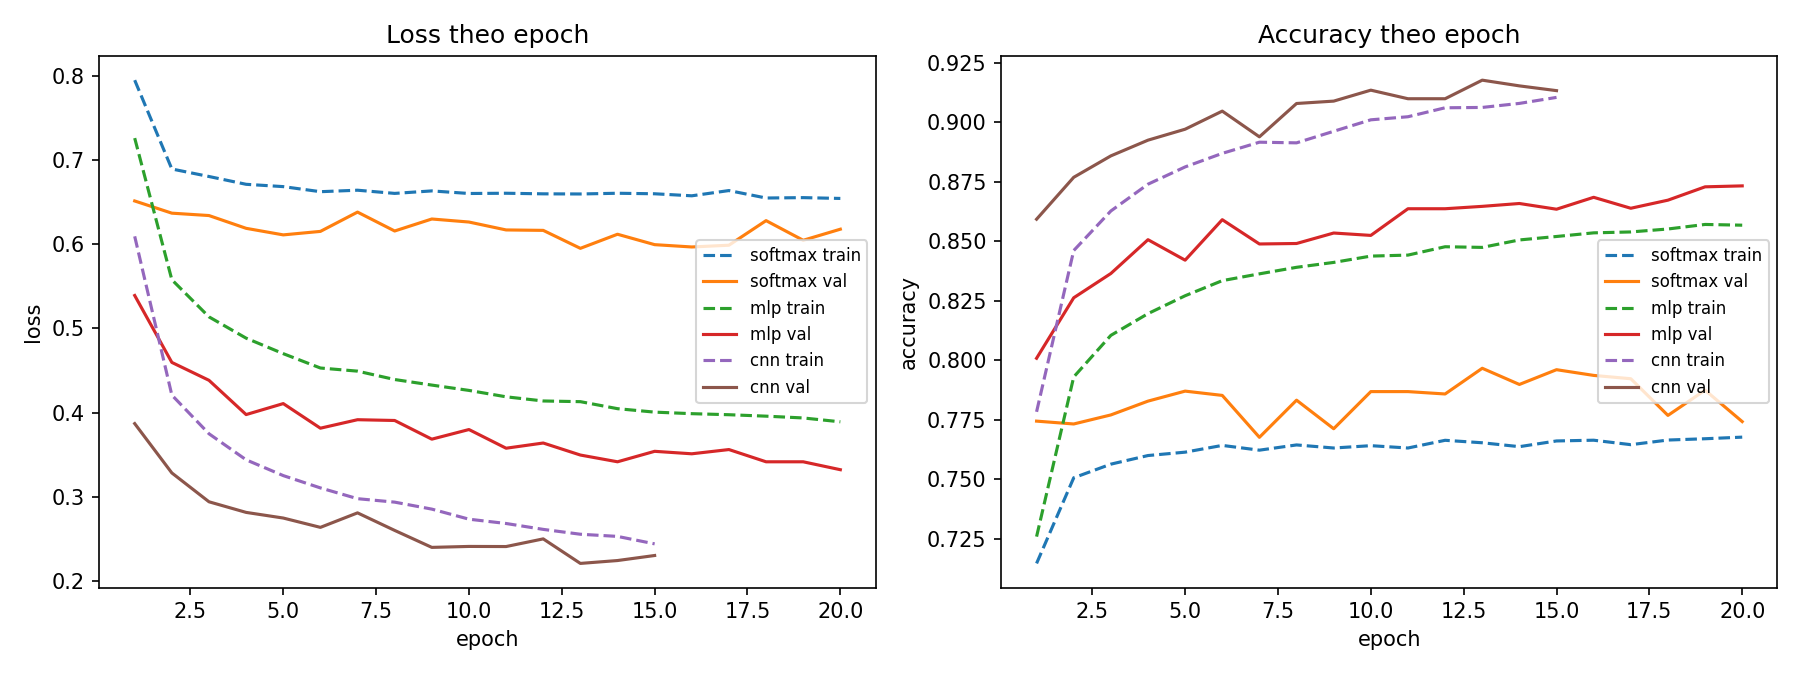

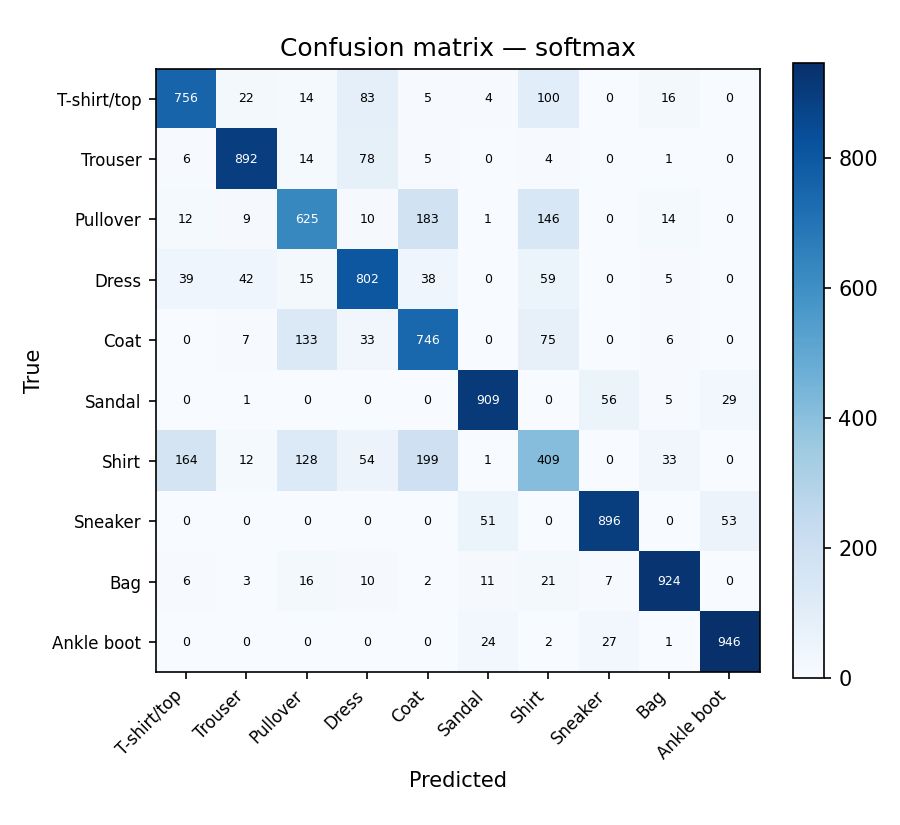

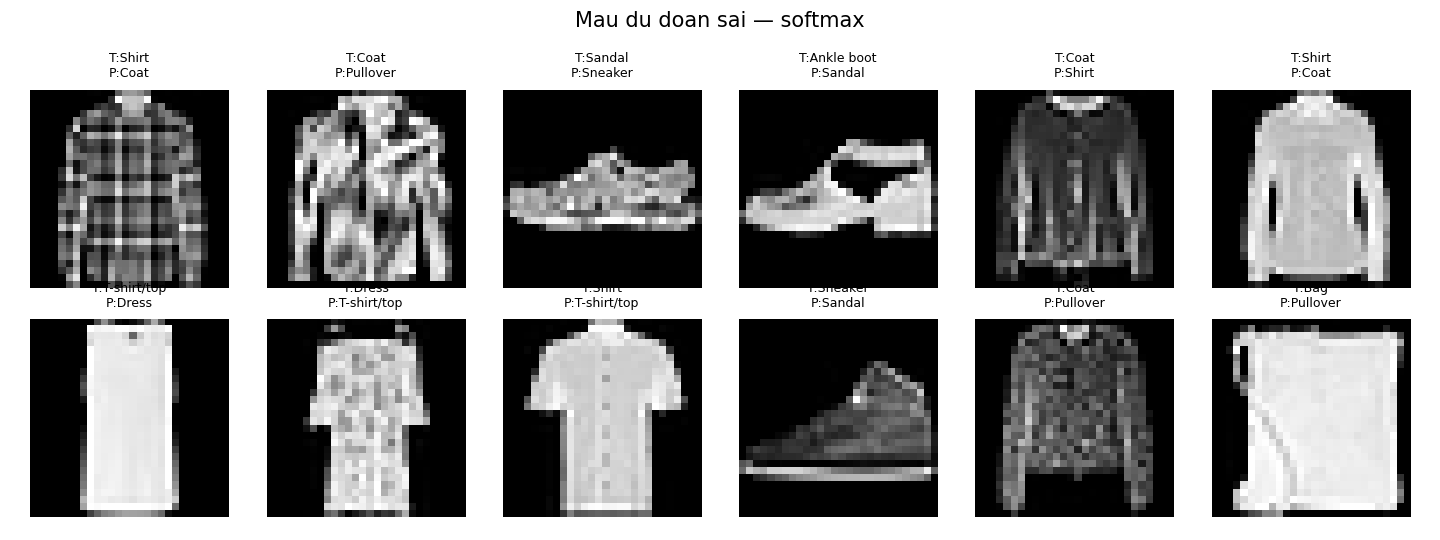

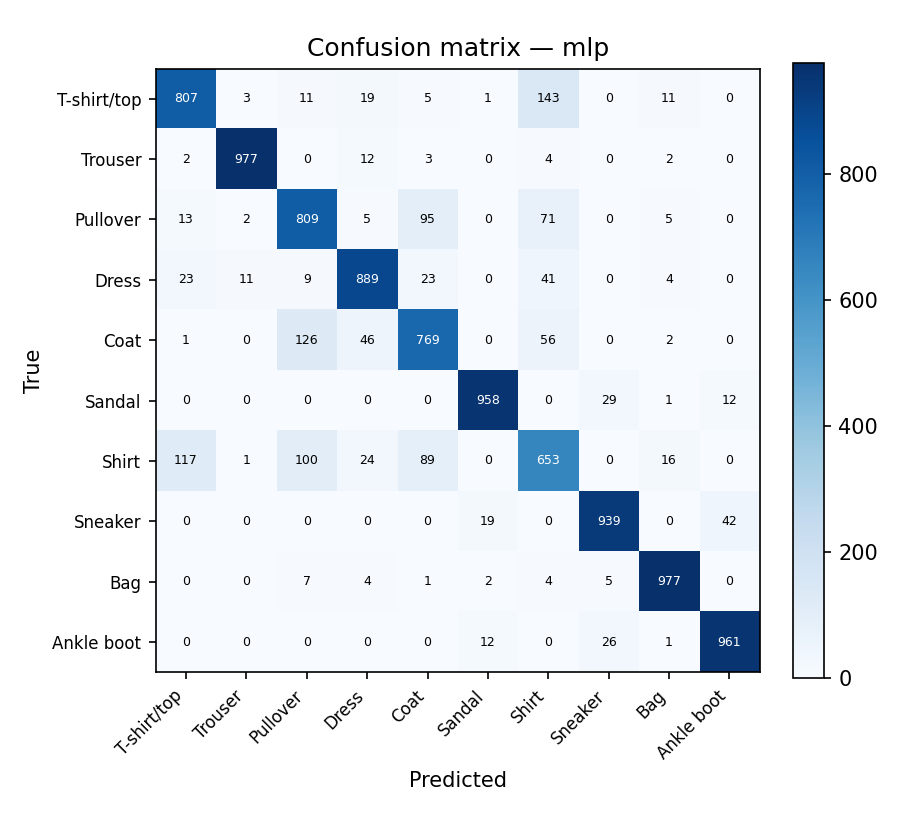

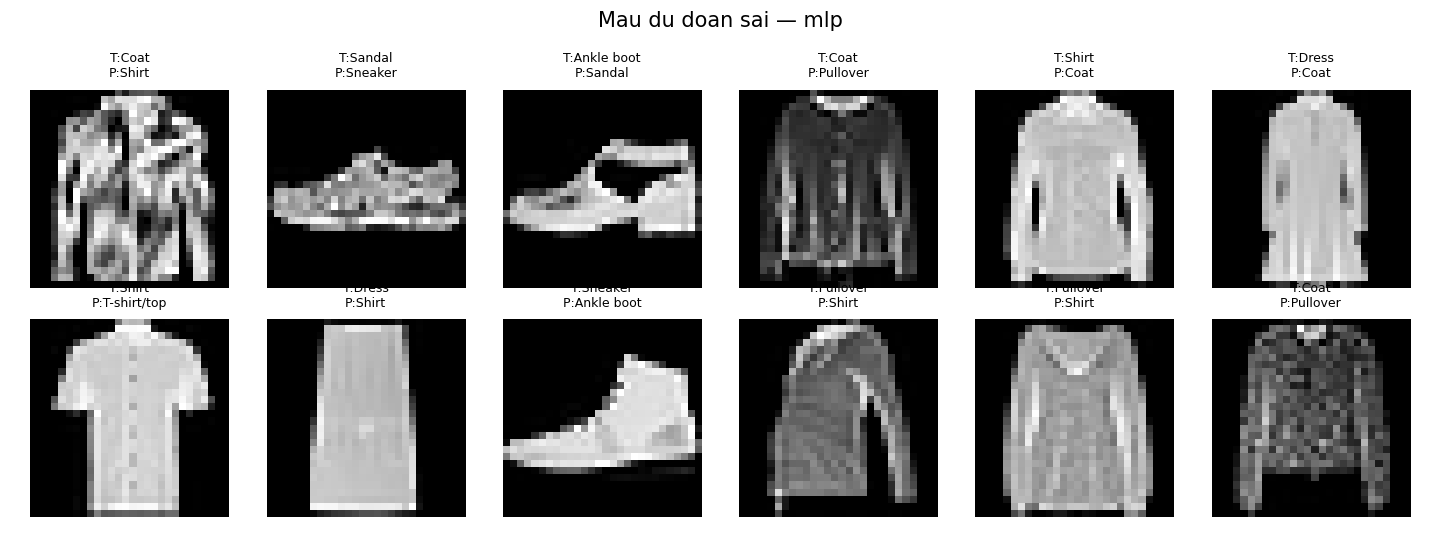

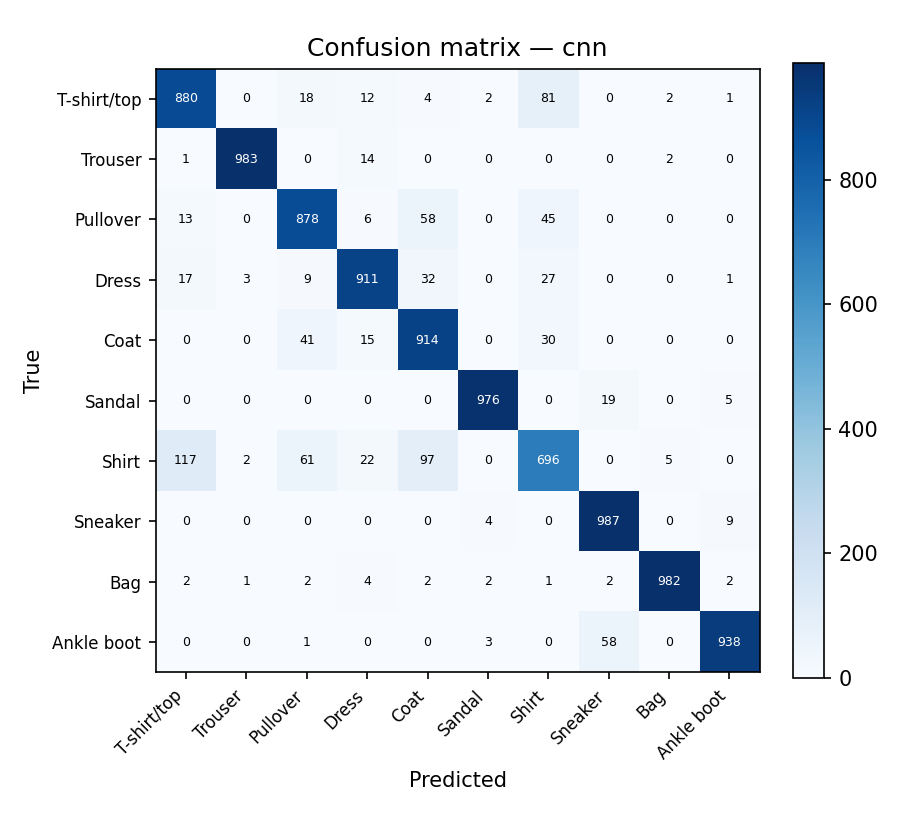

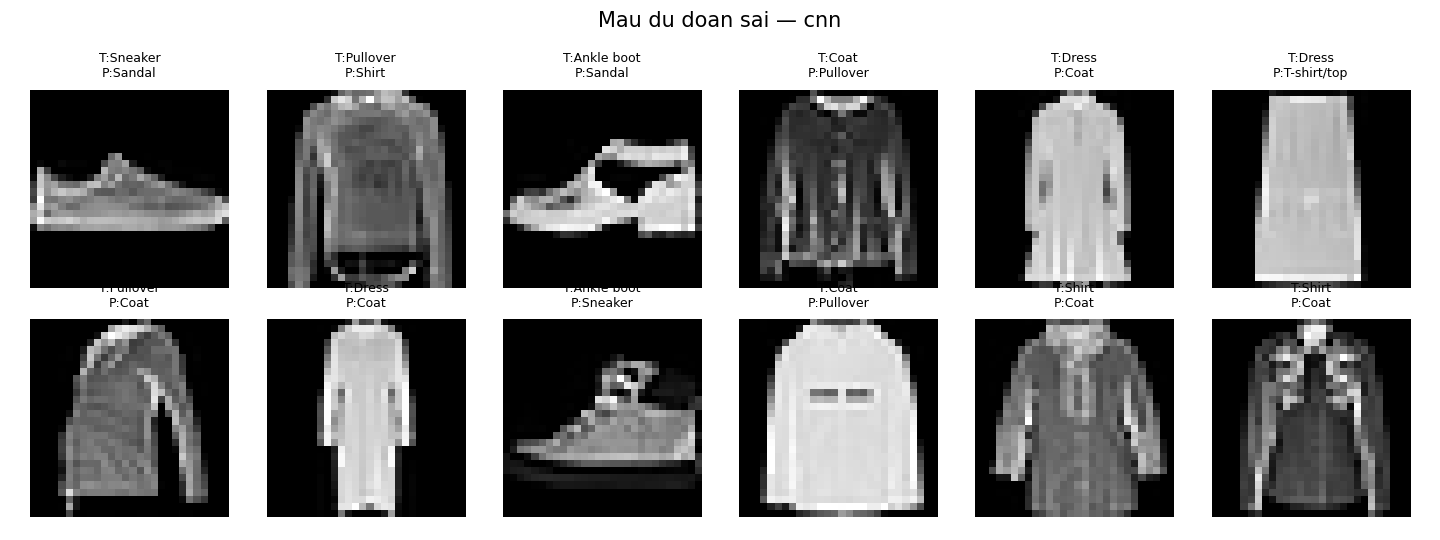

In [9]:
import pandas as pd
from IPython.display import Image, display

display(pd.read_csv("results/comparison_table.csv"))
display(Image("results/loss_accuracy_curves.png"))
for m in ["softmax", "mlp", "cnn"]:
    display(Image(f"results/confusion_matrix_{m}.png"))
    display(Image(f"results/misclassified_{m}.png"))

## 6. Lưu kết quả (Drive hoặc tải về máy)

`results/` chứa checkpoint, log CSV, biểu đồ — dùng cho phần báo cáo E1. Checkpoint (`best.pt`) không commit lên GitHub (xem `.gitignore`), chỉ commit bảng số liệu/biểu đồ cần cho báo cáo.

In [10]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/CO5085_E1_results
!cp -r results /content/drive/MyDrive/CO5085_E1_results/

Mounted at /content/drive


In [11]:
import shutil
from google.colab import files

shutil.make_archive("/content/E1_results", "zip", "results")
files.download("/content/E1_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>